<h1>Import libraries

In [1]:
from pathlib import Path

# Locate shared data from the repository root or any notebook subfolder.
PROJECT_ROOT = next(
    (p for p in (Path.cwd(), *Path.cwd().parents)
     if (p / "data").is_dir() and (p / "1 Data Cleaning").is_dir()),
    None,
)
if PROJECT_ROOT is None:
    raise FileNotFoundError("Open this notebook from within the project folder.")
DATA_DIR = PROJECT_ROOT / "data"

import pandas as pd
import gurobipy as gp
from gurobipy import GRB
import matplotlib.pyplot as plt

<h1>Load Data

In [ ]:
# Load data
df_time_updated = pd.read_csv((DATA_DIR / 'df_time.csv'), index_col=0)
hq_to_locations = pd.read_csv((DATA_DIR / 'hq to locations.csv'), index_col=0)
patrol_timings = pd.read_csv((DATA_DIR / 'patrol timings.csv'), index_col=0)

patrol_timings.head()
df_time_updated.head()
df_time_updated.shape


(304, 304)

<h2> Slice Data

In [ ]:
# # If you want to keep every 10th row only
hq_to_locations = hq_to_locations.iloc[:, ::8]
df_time_updated = df_time_updated.iloc[::8,::8]
patrol_timings = patrol_timings.iloc[::8, :]

# print(patrol_timings.shape)
# print(patrol_timings)

<h2>Check the dataframe

In [4]:
print(patrol_timings.shape)
print(df_time_updated.shape)

(38, 2)
(38, 38)


In [ ]:
patrol_timings

,Places,Amount of time to patrol
1,Bishan East,84
9,Everton Park,84
17,Telok Blangah Way,63
25,Leedon Park,72
33,Marina Centre,90
41,Kallang Way,77
49,Kampong Bugis,81
58,Marine Parade,67
66,Newton Circus,75
74,Somerset,82


In [6]:
df_time_updated

,Bishan East,Everton Park,Telok Blangah Way,Leedon Park,Marina Centre,Kallang Way,Kampong Bugis,Marine Parade,Newton Circus,Somerset,...,Pandan,Lakeside (Business),Hong Kah,Joo Koon,Tuas North,Sembawang Hills,Defu Industrial Park,Tai Seng,Pulau Punggol Barat,Rivervale
index_column,,,,,,,,,,,,,,,,,,,,,
Bishan East,99999,22,19,14,20,12,14,19,13,18,...,17,22,19,29,31,11,13,12,15,19
Everton Park,18,99999,8,18,12,17,17,16,16,12,...,20,24,22,25,28,24,20,17,24,22
Telok Blangah Way,21,11,99999,16,16,20,21,19,20,14,...,19,23,20,24,27,28,23,20,28,25
Leedon Park,15,15,12,99999,19,15,17,22,12,13,...,10,18,14,23,26,16,19,18,22,23
Marina Centre,17,9,10,20,99999,16,13,13,15,11,...,22,26,23,27,29,24,18,16,24,20
Kallang Way,13,23,21,17,17,99999,11,18,11,16,...,20,25,21,31,33,19,14,9,19,20
Kampong Bugis,15,16,14,20,10,13,99999,12,11,12,...,22,28,24,31,34,22,15,13,22,18
Marine Parade,20,16,15,24,15,18,14,99999,17,18,...,27,31,28,32,35,27,18,14,27,20
Newton Circus,12,14,14,11,14,11,12,17,99999,6,...,14,21,18,27,30,18,16,14,18,19


In [7]:
hq_to_locations

,Bishan East,Everton Park,Telok Blangah Way,Leedon Park,Marina Centre,Kallang Way,Kampong Bugis,Marine Parade,Newton Circus,Somerset,...,Pandan,Lakeside (Business),Hong Kah,Joo Koon,Tuas North,Sembawang Hills,Defu Industrial Park,Tai Seng,Pulau Punggol Barat,Rivervale
index_column,,,,,,,,,,,,,,,,,,,,,
Ang Mo Kio Division HQ,9,24,23,20,22,13,16,20,14,20,...,23,29,25,33,34,10,17,15,12,15
Bedok Division HQ,19,23,21,23,22,16,17,14,17,22,...,25,30,27,37,39,25,17,12,24,21
Central Division HQ,20,2,7,17,11,19,19,15,15,11,...,19,23,21,24,27,26,19,16,26,21
Clementi Division HQ,22,17,16,14,22,22,24,25,23,24,...,10,14,12,15,18,24,27,25,31,31
Jurong Division HQ,24,24,21,22,28,24,26,31,23,27,...,17,6,11,12,13,25,28,27,29,32
Tanglin Division HQ,11,15,15,12,14,10,11,16,1,7,...,14,22,18,28,31,18,15,13,18,18
Woodlands Division HQ,20,31,28,23,31,23,25,30,24,28,...,20,23,21,26,26,14,26,24,17,24


<h2>Data cleaning

In [8]:
# Strip whitespace from all names
df_time_updated.index = df_time_updated.index.str.strip()
df_time_updated.columns = df_time_updated.columns.str.strip()
hq_to_locations.index = hq_to_locations.index.str.strip()
hq_to_locations.columns = hq_to_locations.columns.str.strip()
patrol_timings["Places"] = patrol_timings["Places"].str.strip()

In [9]:
df_time_updated

,Bishan East,Everton Park,Telok Blangah Way,Leedon Park,Marina Centre,Kallang Way,Kampong Bugis,Marine Parade,Newton Circus,Somerset,...,Pandan,Lakeside (Business),Hong Kah,Joo Koon,Tuas North,Sembawang Hills,Defu Industrial Park,Tai Seng,Pulau Punggol Barat,Rivervale
index_column,,,,,,,,,,,,,,,,,,,,,
Bishan East,99999,22,19,14,20,12,14,19,13,18,...,17,22,19,29,31,11,13,12,15,19
Everton Park,18,99999,8,18,12,17,17,16,16,12,...,20,24,22,25,28,24,20,17,24,22
Telok Blangah Way,21,11,99999,16,16,20,21,19,20,14,...,19,23,20,24,27,28,23,20,28,25
Leedon Park,15,15,12,99999,19,15,17,22,12,13,...,10,18,14,23,26,16,19,18,22,23
Marina Centre,17,9,10,20,99999,16,13,13,15,11,...,22,26,23,27,29,24,18,16,24,20
Kallang Way,13,23,21,17,17,99999,11,18,11,16,...,20,25,21,31,33,19,14,9,19,20
Kampong Bugis,15,16,14,20,10,13,99999,12,11,12,...,22,28,24,31,34,22,15,13,22,18
Marine Parade,20,16,15,24,15,18,14,99999,17,18,...,27,31,28,32,35,27,18,14,27,20
Newton Circus,12,14,14,11,14,11,12,17,99999,6,...,14,21,18,27,30,18,16,14,18,19


In [10]:
locations = list(df_time_updated.index)
hq_names = list(hq_to_locations.index)
print(locations)
print(hq_names)

['Bishan East', 'Everton Park', 'Telok Blangah Way', 'Leedon Park', 'Marina Centre', 'Kallang Way', 'Kampong Bugis', 'Marine Parade', 'Newton Circus', 'Somerset', 'Ghim Moh', 'Pasir Panjang 2', 'Oxley', 'Rochor Canal', 'Chatsworth', 'Kim Keat', 'Central Water Catchment', 'Sembawang Spring', 'Kranji', 'Woodgrove', 'Northland', 'Bedok Reservoir', 'Changi West', 'Pasir Ris West', 'Tampines West', 'Bukit Batok East', 'Dairy Farm', 'Keat Hong', 'Pandan', 'Lakeside (Business)', 'Hong Kah', 'Joo Koon', 'Tuas North', 'Sembawang Hills', 'Defu Industrial Park', 'Tai Seng', 'Pulau Punggol Barat', 'Rivervale']
['Ang Mo Kio Division HQ', 'Bedok Division HQ', 'Central Division HQ', 'Clementi Division HQ', 'Jurong Division HQ', 'Tanglin Division HQ', 'Woodlands Division HQ']


In [11]:
# Clean up patrol and HQ names
locations = [loc.strip() for loc in locations]
hq_names = [hq.strip() for hq in hq_names]
locations = list(dict.fromkeys(locations))
hq_names = list(dict.fromkeys(hq_names))
print(len(locations))
print(len(hq_names))

38
7


In [12]:
# Combined list of all nodes
V = list(dict.fromkeys(locations + hq_names))
N = locations
H = hq_names

# Patrol time dictionary
s_dict = dict(zip(patrol_timings["Places"], patrol_timings["Amount of time to patrol"]))

# Complete travel time matrix 
T = df_time_updated.copy()
for hq in H:
    T.loc[hq] = hq_to_locations.loc[hq]
    T[hq] = hq_to_locations.loc[hq]
T = T.fillna(99999)

# Parameters
time_limit = 600  # 10 hours
m = 7 # no. of vehicles
K = range(m)


<h1>Gurobi model

In [ ]:
# Gurobi model
model = gp.Model("NightPatrolFeasibility")

# Decision variables
x = model.addVars(V, V, K, vtype=GRB.BINARY, name="x")
a = model.addVars(K, vtype=GRB.CONTINUOUS, name="a")
# y = model.addVars(K, vtype=GRB.BINARY, name="y") # y[k] indicates if a 


# Objective: Minimize total travel time
T_dict = T.fillna(99999).astype(float).to_dict()

model.setObjective(
    gp.quicksum(T_dict[i][j] * x[i, j, k] for k in K for i in V for j in V if i != j),
    GRB.MINIMIZE
)

# # another objective, to minimise number of vehicles
# model.setObjective(gp.quicksum(y[k] for k in K), GRB.MINIMIZE)
# For every hq, m/7 vehicles depart from it
for h in H:
    model.addConstr(
        gp.quicksum(x[h, j, k] for k in K for j in N) == m//7
    )


# the new constraint: If a FRC enters a location, the same FRC has to leave the location.
for i in V:
        for k in K:
            # Sum of incoming arcs to i (g != i)
            incoming = gp.quicksum(x[g, i, k] for g in V if g != i)
            
            # Sum of outgoing arcs from i (j != i)
            outgoing = gp.quicksum(x[i, j, k] for j in V if j != i)
            
            # Add constraint: incoming = outgoing
            model.addConstr(incoming == outgoing, name=f"flow_conservation_{i}_{k}")

# Ensure at most m/7 FRCs are dispatched from each hq
# model.addConstr(gp.quicksum(y[k] for h in H for k in K) == m/7, name="number of FRCS")

# Constraints

# Each location is entered exactly once
for j in N:
    model.addConstr(gp.quicksum(x[i, j, k] for k in K for i in V if i != j) == 1)

# Each location is exited exactly once
for i in N:
    model.addConstr(gp.quicksum(x[i, j, k] for k in K for j in V if i != j) == 1)

# Each FRC starts and ends at the same HQ
for k in K:
    for h in H:
        model.addConstr(
            gp.quicksum(x[h, j, k] for j in N) ==
            gp.quicksum(x[i, h, k] for i in N)
        )

# Each FRC departs from at most one HQ
for k in K:
    model.addConstr(gp.quicksum(x[h, j, k] for h in H for j in N) == 1)


# Time constraints
# Create an index map to access by position
index_map = {node: idx for idx, node in enumerate(T.index)}

for k in K:
    travel_time_terms = [
        T.values[index_map[i], index_map[j]] * x[i, j, k]
        for i in V for j in V if i != j
    ]
    patrol_time_terms = [
        s_dict.get(j, 0) * x[i, j, k]
        for i in V for j in N if i != j
    ]

    travel_time = gp.quicksum(travel_time_terms)
    patrol_time = gp.quicksum(patrol_time_terms)

    model.addConstr(a[k] == travel_time + patrol_time)
    model.addConstr(a[k] <= time_limit)
            

# Create global storage for plotting
time_vals = []
obj_vals = []
bound_vals = []

def subtour_elimination_callback(model, where):
    if where == gp.GRB.Callback.MIPSOL:
        # Track the best solution and lower bound against time
        t = model.cbGet(gp.GRB.Callback.RUNTIME)
        obj = model.cbGet(gp.GRB.Callback.MIPSOL_OBJ)
        bound = model.cbGet(gp.GRB.Callback.MIPSOL_OBJBND)

        time_vals.append(t)
        obj_vals.append(obj)
        bound_vals.append(bound)

        # Subtour elimination logic
        x_vals = model.cbGetSolution(model._x)
        N_list = list(model._N)
        K_list = list(model._K)

        for k in K_list:
            edges = [(i, j) for i in N_list for j in N_list if i != j and x_vals[i, j, k] > 0.5]

            unvisited = set(N_list)
            while unvisited:
                current_subtour = []
                this_node = unvisited.pop()
                stack = [this_node]
                while stack:
                    node = stack.pop()
                    if node not in current_subtour:
                        current_subtour.append(node)
                        for _, j in edges:
                            if _ == node and j in unvisited:
                                stack.append(j)
                                unvisited.remove(j)
                if 2 <= len(current_subtour) < len(N_list):
                    expr = gp.quicksum(model._x[i, j, k] for i in current_subtour for j in current_subtour if i != j)
                    model.cbLazy(expr <= len(current_subtour) - 1)



Set parameter Username
Set parameter LicenseID to value 2650922
Academic license - for non-commercial use only - expires 2026-04-13


<h2>Run Gurobi model

In [ ]:
import time

# Set time limit 
model.setParam("TimeLimit", 18000)
model.setParam('LogFile', str(PROJECT_ROOT / '3 Solving a Smaller Instance' / 'my_gurobi_log.log'))

# for the subtour constraint
model.Params.LazyConstraints = 1
model._x = x  # x[i,j,k] variable dictionary
model._N = N  # list of location names (not HQs)
model._K = K  # range or list of vehicle indices
model.optimize(subtour_elimination_callback)


# Results
if model.SolCount > 0:
    print("Optimal solution found." if model.status == GRB.OPTIMAL else "Feasible incumbent found; optimality not proven.")
    print("Total travel time:", model.ObjVal)
else:
    print("❌ No feasible solution found.")

Set parameter TimeLimit to value 18000
Set parameter LogFile to value "my_gurobi_log.log"
Set parameter LazyConstraints to value 1
Gurobi Optimizer version 12.0.2 build v12.0.2rc0 (win64 - Windows 11.0 (26100.2))

CPU model: AMD Ryzen 7 7730U with Radeon Graphics, instruction set [SSE2|AVX|AVX2]
Thread count: 8 physical cores, 16 logical processors, using up to 16 threads

Non-default parameters:
TimeLimit  18000
LazyConstraints  1

Optimize a model with 468 rows, 14182 columns and 72450 nonzeros
Model fingerprint: 0x2d7d4ce6
Variable types: 7 continuous, 14175 integer (14175 binary)
Coefficient statistics:
  Matrix range     [1e+00, 1e+05]
  Objective range  [1e+00, 1e+05]
  Bounds range     [1e+00, 1e+00]
  RHS range        [1e+00, 6e+02]
Presolve removed 56 rows and 294 columns
Presolve time: 0.16s
Presolved: 412 rows, 13888 columns, 67550 nonzeros
Variable types: 0 continuous, 13888 integer (13881 binary)

Root relaxation: objective 4.040000e+02, 696 iterations, 0.09 seconds (0.08 

In [20]:
# Print which vehicles are used, their total time, and their routes
if model.SolCount > 0:
    print("Objective value:", model.ObjVal)
    for k in K:
        print(f"\nVehicle {k} is used.")
        print(f"  Total time (a[{k}]): {a[k].X:.2f}")
        print(f"  Route for vehicle {k}:")
        for i in V:
            for j in V:
                if i != j and x[i, j, k].X > 0.5:
                    print(f"    {i} -> {j}")
else:
    print("❌ No feasible solution found.")

Objective value: 454.0

Vehicle 0 is used.
  Total time (a[0]): 520.00
  Route for vehicle 0:
    Bukit Batok East -> Keat Hong
    Keat Hong -> Joo Koon
    Lakeside (Business) -> Hong Kah
    Hong Kah -> Bukit Batok East
    Joo Koon -> Tuas North
    Tuas North -> Jurong Division HQ
    Jurong Division HQ -> Lakeside (Business)

Vehicle 1 is used.
  Total time (a[1]): 533.00
  Route for vehicle 1:
    Bishan East -> Ang Mo Kio Division HQ
    Kallang Way -> Kim Keat
    Kim Keat -> Bishan East
    Defu Industrial Park -> Kallang Way
    Pulau Punggol Barat -> Rivervale
    Rivervale -> Defu Industrial Park
    Ang Mo Kio Division HQ -> Pulau Punggol Barat

Vehicle 2 is used.
  Total time (a[2]): 554.00
  Route for vehicle 2:
    Marine Parade -> Changi West
    Bedok Reservoir -> Tai Seng
    Changi West -> Pasir Ris West
    Pasir Ris West -> Tampines West
    Tampines West -> Bedok Reservoir
    Tai Seng -> Bedok Division HQ
    Bedok Division HQ -> Marine Parade

Vehicle 3 is use

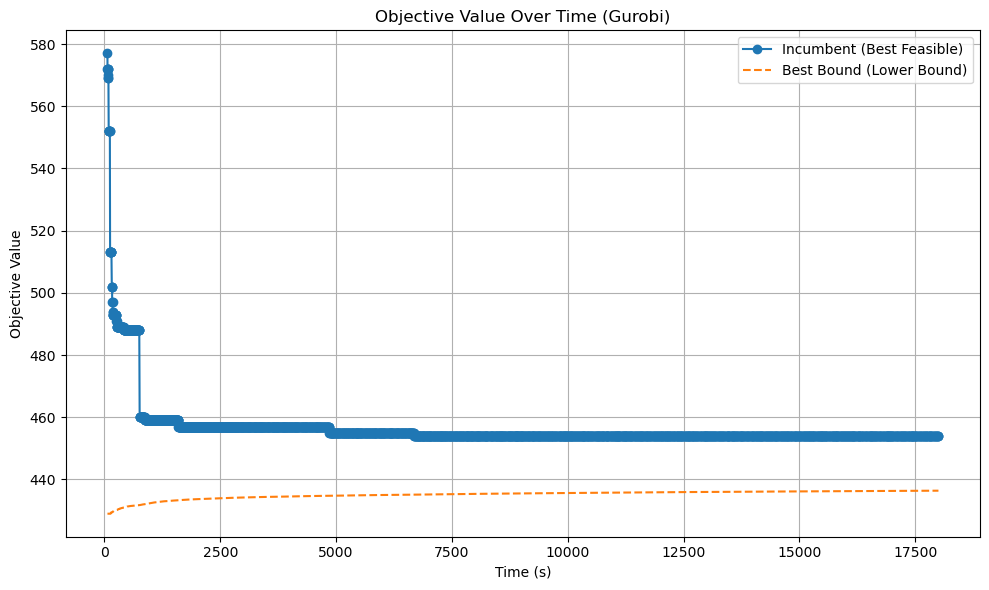

In [25]:
import re
import matplotlib.pyplot as plt

# File path to your Gurobi log
logfile_path = PROJECT_ROOT / '3 Solving a Smaller Instance' / 'my_gurobi_log.log'

# Lists to store the extracted data
time_vals = []
incumbent_vals = []
bestbd_vals = []

# Patterns
incumbent_line = re.compile(r'^\s*(?:\*|H)?\s*\d+\s+\d+.*?(\d+\.\d+)\s+(\d+\.\d+)\s+\d+\.\d+%\s+[\d\.]+\s+(\d+)s')
no_incumbent_line = re.compile(r'^\s*\d+\s+\d+\s+[\d\.]+\s+\d+\s+\d+.*?-+\s+(\d+\.\d+)\s+-+\s+[\d\.]+\s+(\d+)s')

with open(logfile_path, "r") as file:
    for line in file:
        match = incumbent_line.search(line)
        if match:
            inc = float(match.group(1))
            bd = float(match.group(2))
            t = float(match.group(3))
            incumbent_vals.append(inc)
            bestbd_vals.append(bd)
            time_vals.append(t)
        else:
            match2 = no_incumbent_line.search(line)
            if match2:
                bd = float(match2.group(1))
                t = float(match2.group(2))
                # Repeat the last incumbent if any
                if incumbent_vals:
                    inc = incumbent_vals[-1]
                    incumbent_vals.append(inc)
                    bestbd_vals.append(bd)
                    time_vals.append(t)

# Plotting
plt.figure(figsize=(10, 6))
plt.plot(time_vals, incumbent_vals, label="Incumbent (Best Feasible)", marker='o')
plt.plot(time_vals, bestbd_vals, label="Best Bound (Lower Bound)", linestyle='--')
plt.xlabel("Time (s)")
plt.ylabel("Objective Value")
plt.title("Objective Value Over Time (Gurobi)")
plt.legend()
plt.grid(True)
plt.tight_layout()
plt.show()
